# Optimización de controladores PID mediante Algoritmos Genéticos

**Autores**: Raul Matei Plohod y Daniel Navarro Puche  
**Asignatura**: Robótica — Grado en Ciencia de Datos, UPM  
**Chats LLMs**: [Archivo llm-chats.md](llm-chats.md)

## 0. Instalación

Las dependencias se gestionan con [uv](https://docs.astral.sh/uv/). Teniendo todos los archivos en un directorio, basta con :

```bash
uv sync
```

Esto creará el entorno virtual e instalará todas las dependencias declaradas en `pyproject.toml`. La librería `genetic-metaheuristics` se descargará automáticamente desde su repositorio público de GitHub.

### Dependencias

> Requiere Python ≥ 3.12.

| Paquete | Versión mínima | Fuente |
|---------|---------------|--------|
| `genetic-metaheuristics` | 0.1.0 | GitHub (SSH) |
| `ipykernel` | 7.2.0 | PyPI |
| `matplotlib` | 3.10.8 | PyPI |  

  

## 1. Introducción

El objetivo de esta práctica es optimizar automáticamente las ganancias $K_p$, $K_i$ y $K_d$ de un controlador PID para un motor de corriente continua (DC), usando un **algoritmo genético** como método de búsqueda metaheurística.

En la práctica anterior hemos implementado el controlador PID y ajustamos sus parámetros manualmente, observando su efecto sobre los índices de rendimiento. Ese proceso es laborioso y no garantiza el óptimo global. Los algoritmos genéticos permiten automatizar esa búsqueda explorando el espacio de parámetros de forma paralela y sin necesidad de conocer el modelo matemático exacto del sistema.

### Planteamiento del problema

Se trata de un problema de **optimización continua en $\mathbb{R}^3$**: encontrar el vector $(K_p, K_i, K_d)$ que minimiza una función de coste basada en los índices de rendimiento de la respuesta del controlador ante un escalón de velocidad de $0$ a $50$ km/h.

## 2. Modelo del sistema

### 2.1. Motor de corriente continua (DC)

El sistema a controlar es un motor DC cuya dinámica discreta (periodo de muestreo $T = 0{,}0001$ s) viene dada por:

$$\omega[k] = 0{,}999755 \cdot \omega[k-1] + 14{,}769238 \cdot K \cdot i[k-1]$$

$$i[k] = 0{,}574072 \cdot i[k-1] + 0{,}383719 \cdot (u[k] - K \cdot \omega[k])$$

donde $\omega$ es la velocidad angular (rad/s), $i$ es la corriente (A), $u$ es la tensión de alimentación (V) y $K = 0{,}0364$ Nm/A es la constante del motor. La tensión está saturada entre $-24$ V y $+24$ V para modelar los límites de la batería.

Los parámetros físicos del motor son:

| Parámetro | Valor | Unidades |
|-----------|-------|----------|
| Resistencia $R$ | 1,11 | Ω |
| Inductancia $L$ | 0,0002 | H |
| Inercia $J$ | 6,77·10⁻⁶ | kg·m² |
| Fricción viscosa $f_v$ | 1,66·10⁻⁵ | Nm·s/rad |
| Constante $K$ | 0,0364 | Nm/A |

### 2.2. Controlador PID

El controlador PID calcula la señal de control $u(t) = P + I + D$ a partir del error $e(t) = r(t) - \omega(t)$:

- **Componente proporcional:** $P = K_p \cdot e(t)$
- **Componente integral (discreta):** $I[k] = I[k-1] + K_i \cdot e[k] \cdot h$, donde $h = 0{,}001$ s es el periodo de muestreo del controlador.
- **Componente derivativa filtrada:** Para atenuar el ruido de medida se usa un filtro de primer orden con constante de tiempo derivativa $T_d = K_d/K_p$ y factor de filtrado $N \in [8, 20]$:

$$D[k] = \frac{T_d}{T_d + Nh} \cdot D[k-1] + \frac{K_d \cdot N}{T_d + Nh} \cdot (e[k] - e[k-1])$$

El controlador opera a $f_c = 1/h = 1000$ Hz. Se simulan 320 ciclos del controlador (0,32 s de tiempo real).

In [1]:
import stat, random
class DCMotorSim:
    def __init__(self):
        self.R = 1.11  # Ohm
        self.L = 0.0002  # H
        self.J = 6.77E-6  # Kgm²
        self.fv = 1.66E-5  # Nm/(Rad/s)
        self.K = 0.0364  # Nm/A or V/(Rad/s)
        self.voltage = 0.0
        self.w = [0.0, 0.0]  # tk speed
        self.i = [0.0, 0.0]  # tk current

    def init(self):
        self.R = 1.11
        self.L = 0.0002
        self.J = 6.77E-6
        self.fv = 1.66E-5
        self.K = 0.0364
        self.voltage = 0.0
        self.w = [0.0, 0.0]
        self.i = [0.0, 0.0]

    def set_voltage(self, new_voltage):
        self.voltage = new_voltage
        # Saturation effect due to battery limits
        if self.voltage > 24.0:
            self.voltage = 24.0
        if self.voltage < -24.0:
            self.voltage = -24.


    def get_speed(self): 
        return self.w[0]

    def exec_cycle(self):
        # Motor behavior considering T = 0.0001s
        self.w[0] = self.w[1]
        self.i[0] = self.i[1]
        self.w[1] = 0.999755 * self.w[0] + 14.769238 * self.K * self.i[0]
        self.i[1] = 0.574072 * self.i[0] + 0.383719 * (self.voltage - self.K * self.w[1])
        

class Controller:
    def __init__(self):
        self.Kp = 0.0
        self.Ki = 0.0
        self.Kd = 0.0
        self.reference_speed = 0.0
        self.controller_t = 0.001
        self.motor_sim = DCMotorSim()
        self.motor_speed_anterior = 0
        self.previous_I = 0
        self.previous_D = 0
        self.proportions = []
        self.integrals = []
        self.derivatives = []
        self.registry = dict()  # For later gradient-based optimization
        
    def init(self, new_Kp: float, new_Ki: float, new_Kd: float):
        self.Kp = new_Kp
        self.Ki = new_Ki
        self.Kd = new_Kd
        
        # Reiniciar las variables de estado del PID
        self.motor_speed_anterior = 0.0
        self.previous_I = 0.0
        self.previous_D = 0.0
        self.proportions = []
        self.integrals = []
        self.derivatives = []

        # Inicializar el motor
        self.motor_sim.init()
        

    def set_reference(self, speed: float):
        self.reference_speed = speed

    def exec_controller_cycle(self, noisy: bool = True):
        # Compute control parameters
        motor_speed = DCMotorSim.get_speed(self.motor_sim)


        error = self.reference_speed - motor_speed
        error_anterior = self.reference_speed - self.motor_speed_anterior
        
        P = self.Kp * error
        self.proportions.append(error)
        I = self.previous_I + self.Ki * error * self.controller_t
        self.integrals.append(I / self.Ki if abs(self.Ki) > 1e-10 else error * self.controller_t)
        
        if not noisy and abs(self.Kd) > 1e-10:
            # Based on finite difference derivative approximation via Taylor expansion
            # but including the derivative since we are already saving it
            # f(x - h) = f(x) - h * f'(x) + h^2/2 * f''(x) - h^3/6 * f'''(x) + ...
            # f'(x-h) = f'(x) - h * f''(x) + h^2/2 * f'''(x) - h^3/6 * f''''(x) + ...
            
            # f(x) - f(x - h) = h * f'(x) - h^2/2 * f''(x) + h^3/6 * f'''(x) - ...
            # 2f(x) - 2f(x - h) - h * f'(x-h) = h * f'(x) - h^3/3 * f'''(x) + ...
            # Solving for f'(x): f'(x) = 2 * (f(x) - f(x - h)) / h - f'(x-h) + h^2/3 * f'''(x) - ...
            # Which in practice is: f'(x) = 2 * (f(x) - f(x - h)) / h - f'(x-h) + O(h^2) (for small enough h)
            D = 2 * (error - error_anterior) / self.controller_t - self.previous_D / self.Kd
            
            # However, noise can cause big errors in this approximation

        elif abs(self.Kp) < 1e-10 or abs(self.Kd) < 1e-10:
            D = 0
        else:
            Td = self.Kd / self.Kp
            N = 10  # Noise filter (normally between 8-20)
            h = self.controller_t
            
            denominator = Td + N * h
            term1 = Td / (Td + N * h) * self.previous_D
            term2 = self.Kd * N / denominator * (error - error_anterior)
            D = term1 + term2
            
        self.derivatives.append(D / self.Kd if abs(self.Kd) > 1e-10 else (error - error_anterior) / self.controller_t)
        
        # Prepare last error for next cycle       
        self.motor_speed_anterior = motor_speed

        # Prepare last I and D for next cycle
        self.previous_I = I
        self.previous_D = D
        
        # Compute controller output
        new_motor_voltage = P+I+D
        DCMotorSim.set_voltage(self.motor_sim, new_motor_voltage)
        DCMotorSim.exec_cycle(self.motor_sim)

        return motor_speed, new_motor_voltage
    
    def calculate_gradients(self):
        proportions_mean = stat.mean(self.proportions)
        integrals_mean = stat.mean(self.integrals)
        derivatives_mean = stat.mean(self.derivatives)

        self.registry[tuple((self.Kp, self.Ki, self.Kd))] = (proportions_mean, integrals_mean, derivatives_mean)
        return proportions_mean, integrals_mean, derivatives_mean
    
    
from math import ceil
import numpy as np
import statistics as stat

class Performance:    
    def __init__(self):
        self.overshoot = 0.0
        self.decay_ratio = 0.0
        self.steady_state_error = 0.0
        self.time_to_settle = 0.0
        self.v = []
        self.ref_v = 0.0

    def init(self, velocidades: list[float], velocidad_de_referencia: float):
        self.overshoot = 0.0
        self.decay_ratio = 0.0
        self.steady_state_error = 0.0
        self.time_to_settle = 0.0
        self.v = velocidades
        self.ref_v = velocidad_de_referencia
        
    def get_crossings(self) -> list[int]:
        crossings = []
        for i in range(len(self.v)-1):
            if (self.v[i] - self.ref_v) * (self.v[i+1] - self.ref_v) < 0:  # Check for crossing
                crossings.append(i)
        return crossings
    
    def get_peaks(self) -> list[int]:
        peaks = []
        for i in range(1, len(self.v)-1):
            if self.v[i] > self.v[i-1] and self.v[i] > self.v[i+1]:
                peaks.append(i)
        return peaks
    
    def calculate_overshoot(self) -> float:
        initial_speed = self.v[0]
        overshoot_speed = max(self.v) if initial_speed < self.ref_v else min(self.v)
        A = overshoot_speed - self.ref_v
        B = initial_speed - self.ref_v
        if A * B < 0:  # Check if there is an overshoot in the opposite direction of the initial speed
            return - A / B
        else:
            return 0
    
    def calculate_decay_ratio(self, peaks: list[int] | None = None) -> float:
        # We can calculate it if there are at least 2 peaks
        peaks = self.get_peaks() if peaks is None else peaks
        if len(peaks) < 2:
            return 0
        
        c = self.v[-1]
        total = 1
        for i in range(len(peaks)-1):
            total *= abs(self.v[peaks[i+1]] - c) / abs(self.v[peaks[i]] - c)
            
        return total ** (1/(len(peaks)-1))  # Geometric mean of the ratios since it multiplicatively decay
    
    def calculate_time_to_settle(self, crosses: list[int] | None = None, peaks: list[int] | None = None) -> float:
        crosses = self.get_crossings() if crosses is None else crosses
        peaks = self.get_peaks() if peaks is None else peaks
        max_time = len(self.v)
        if getattr(self, 'decay_ratio', None) is None:
            self.decay_ratio = self.calculate_decay_ratio(peaks)
            
        if self.decay_ratio >= 1:  # No decay, so it doesn't settle
            return 1

        band = 0.02 * self.ref_v  # 2% value reference
        sup_limit = self.ref_v + band
        inf_limit = self.ref_v - band
        if len(crosses) > 1:
            # Estimate it interpolating geometrically between peaks
            # f(x) = 1 / (d^(x/T)) * C + offset
            # (f(x) - offset) * d^(x/T) = C
            offset = self.v[-1]
            period = stat.mean(peaks)
            C = stat.mean((self.v[i] - offset) * self.decay_ratio ** (i / period) for i in peaks)
            
            # Now we cross it with the bands by solving for x in f(x)
            # C / (f(x) - offset) = d^(x/T)
            # log(C / (f(x) - offset)) / log(d) * T = x
            
            denominator_inf = - inf_limit - offset
            denominator_sup = sup_limit - offset
            x_inf = float('inf')
            if denominator_inf != 0 and C / denominator_inf > 0:
                x_inf = (np.log(C / denominator_inf) / np.log(self.decay_ratio)) * period
            
            x_sup = float('inf')
            if denominator_sup != 0 and C / denominator_sup > 0:
                x_sup = (np.log(C / denominator_sup) / np.log(self.decay_ratio)) * period
                
            time_to_settle = min(x_inf, x_sup)
            
        else:
            time_to_settle = len(self.v)
            for i in range(len(self.v))[::-1]:
                if self.v[i] > sup_limit or self.v[i] < inf_limit:
                    time_to_settle = i + 1
                    break
            
            if time_to_settle == len(self.v):  # Doesn't settle in time
                time_to_settle = max_time
        
        # If it's amplitud increases that means no settling
        return time_to_settle / max_time if time_to_settle > 0 else 1
    
    def calculate_steady_state_error(self, time_to_settle: float | None = None) -> float:
        time_to_settle = self.calculate_time_to_settle() if time_to_settle is None else time_to_settle
        
        # Weird comparison because it might be infinite or just barely bigger
        if time_to_settle > len(self.v) or ceil(time_to_settle) >= len(self.v):
            return 1
        
        return stat.mean(abs(self.v[i] - self.ref_v) for i in range(ceil(time_to_settle), len(self.v))) / self.ref_v
    
        
    def calcula_indexes(self):
        crosses = self.get_crossings()
        peaks = self.get_peaks()
   
        self.overshoot = self.calculate_overshoot()
        self.decay_ratio = self.calculate_decay_ratio(peaks)
        self.time_to_settle = self.calculate_time_to_settle(crosses, peaks)
        self.steady_state_error = self.calculate_steady_state_error(self.time_to_settle)

        return self.overshoot, self.decay_ratio, self.steady_state_error, self.time_to_settle


## 3. Índices de rendimiento

Para poder evaluar cuantitativamente la calidad de una respuesta, se calculan cuatro índices estándar de la teoría de control:

| Índice | Símbolo | Descripción |
|--------|---------|-------------|
| Sobreimpulso (*overshoot*) | $O$ | Cociente entre el primer pico y el valor final: $O = A/B$ |
| Ratio de decaimiento | $d$ | Media geométrica de los ratios entre picos consecutivos; $d < 1$ implica oscilaciones amortiguadas |
| Error en régimen estacionario | $E_{ss}$ | Error medio (relativo) una vez que la respuesta ha entrado en la banda del $\pm 2\%$ |
| Tiempo de estabilización | $T_s$ | Tiempo normalizado hasta que la respuesta permanece dentro de la banda del $\pm 2\%$ del setpoint |

La función de *fitness* a minimizar es la suma de los cuatro índices:

$$\mathcal{F}(K_p, K_i, K_d) = O + d + E_{ss} + T_s$$

Todos los términos están normalizados en $[0, 1]$ aproximadamente, por lo que contribuyen de forma equilibrada. El mínimo teórico es $0$ (respuesta perfecta e instantánea sin oscilaciones).

> **Nota de implementación:** $T_s$ se estima extrapolando geométricamente la envolvente de los picos cuando hay más de un cruce de la referencia, o buscando la última muestra fuera de banda en caso contrario. Los índices se almacenan en la clase `Performance`.

## 4. Algoritmo Genético

### 4.1. Codificación del cromosoma

Cada individuo es un vector de tres números reales:

$$\text{cromosoma} = [K_p,\ K_i,\ K_d] \in \mathbb{R}^3$$


### 4.2. Parámetros del AG

| Parámetro | Valor | Justificación |
|-----------|-------|---------------|
| Tamaño de la población $N$ | 100 | Balance exploración/coste computacional |
| Número de generaciones | 200 | Suficiente para converger en este espacio 3D |
| Probabilidad de cruce $p_c$ | 0,6 | Valor estándar para AGs con reales |
| Probabilidad de mutación $p_m$ | 0,1 | Baja para preservar soluciones decentes |
| Operador de mutación | Gaussiano ($\sigma = 0{,}01$) | Perturbaciones pequeñas alrededor del gen actual |
| Participantes en torneo $T$ | 2 | Presión selectiva moderada |
| Semilla aleatoria | 1234 | Reproducibilidad de resultados |

La mutación gaussiana aplica $K_i' = K_i + \mathcal{N}(0, \sigma)$ a cada gen seleccionado para mutación, lo que favorece la exploración local alrededor de buenas soluciones.

In [2]:
from genetic_metaheuristics.metaheuristics.reals import RealsMetaheuristicGeneticOptimizer
from numpy import ndarray

class PIDGeneticOptimizer(RealsMetaheuristicGeneticOptimizer):
            
    def set_controller(self, controller: Controller):
        self.controller = controller
        
    def set_performance(self, performance: Performance):
        self.performance = performance

    def calculate_gene_fitness(self, gene: ndarray) -> float:
        Kp, Ki, Kd = gene
        self.controller.init(Kp, Ki, Kd)
        self.controller.set_reference(50.0)
        
        velocidades = []
        for _ in range(320):
            motor_speed, new_motor_voltage = self.controller.exec_controller_cycle()
            velocidades.append(motor_speed)
        
        # Update registry (for later gradient-based optimization)
        self.controller.calculate_gradients()
        
        # Calculate performance indices
        self.performance.init(velocidades, self.controller.reference_speed)
        overshoot, decay_ratio, steady_state_error, time_to_settle = self.performance.calcula_indexes()
        
        # Return a fitness value based on the performance indices (e.g., minimize overshoot and settling time)
        fitness = overshoot + decay_ratio + steady_state_error + time_to_settle
        
        return fitness

Dibujar el resultado de la optimización mediante el algoritmo genético. No tocar

In [3]:
from matplotlib import pyplot as plt

class dibujacontrol:
    

    def dibujar (self, Kp, Ki, Kd):
        
        fig, ax = plt.subplots()
        fig, ax2 = plt.subplots()
        P = Performance()  
        
        # Crear una instancia del controlador
        controller = Controller()

        
        velocidad=[]
        ut=[]
        coordenadax=[]

        Velocidad_de_referencia = 50.0
        
        # Inicializar el controlador con los valores de ganancia
        controller.init(Kp, Ki, Kd)

        # Establecer la velocidad de referencia
        controller.set_reference(Velocidad_de_referencia)

        # Ejecutar 320 ciclos del controlador
        for ite in range(320):
            x,y = controller.exec_controller_cycle()
            velocidad.append(x)
            ut.append(y)
            coordenadax.append(ite)
        
        ax.set_title("Salida del Sistema")  
        ax.plot(coordenadax, velocidad, linewidth=2.0)
        ax.grid(axis='x', color='0.95')
        ax.grid(axis='y', color='0.95')
        ax2.set_title("Señal de control")
        ax2.plot(coordenadax, ut, linewidth=2.0)
        ax2.grid(axis='x', color='0.95')
        ax2.grid(axis='y', color='0.95')

        P.init(velocidad, Velocidad_de_referencia)
        o, d, Ess, Ts = P.calcula_indexes()
        print("Overshoot: ",o)
        print("d: ",d)
        print("Ess: ",Ess)
        print("Ts:", Ts)

### 4.3. Configuración e inicialización

Se instancia el optimizador con los parámetros descritos en la tabla anterior. La población inicial se genera aleatoriamente dentro de los rangos predeterminados por la librería para variables reales.

In [4]:
pid_genetic_optimizer = PIDGeneticOptimizer(
    gene_length=3,
    cross_prob=0.6,
    mut_prob=0.1,
    tournament_participants=2,
    operator='gaussian',
    gaussian_mutation_scale=1e-2,
    maximize=False,
    seed=None,
    on_keyboard_interrupt='raise',
    max_workers=None
)

pid_genetic_optimizer.set_controller(Controller())
pid_genetic_optimizer.set_performance(Performance())

### 4.4. Ejecución del algoritmo genético

Se ejecutan 200 generaciones sobre una población de 100 individuos. Las semillas de NumPy y del módulo `random` se fijan para garantizar la reproducibilidad.

In [5]:
population = pid_genetic_optimizer.create(N=100)
random.seed(1234)
np.random.seed(1234)
population = pid_genetic_optimizer.evolve(population, num_generations=200) # type: ignore

Generaciones:   0%|          | 0/200 [00:00<?, ?it/s]

Generaciones: 100%|██████████| 200/200 [00:39<00:00,  5.10it/s]


Fitness óptimo: 1.465
Mejor individuo [-0.00136834  0.16529282  0.32970772]


### 4.5. Resultado del AG estándar

El primer elemento de la población devuelta es el mejor individuo encontrado (la librería mantiene la población ordenada por *fitness*). Se muestran las ganancias óptimas y la respuesta del controlador resultante.

Mejor cromosoma: [-0.00136834  0.16529282  0.32970772]
Overshoot:  0.018755945341179796
d:  0
Ess:  0.5117683324366891
Ts: 0.934375


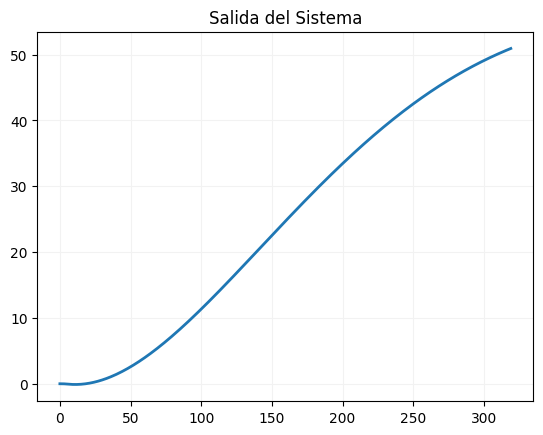

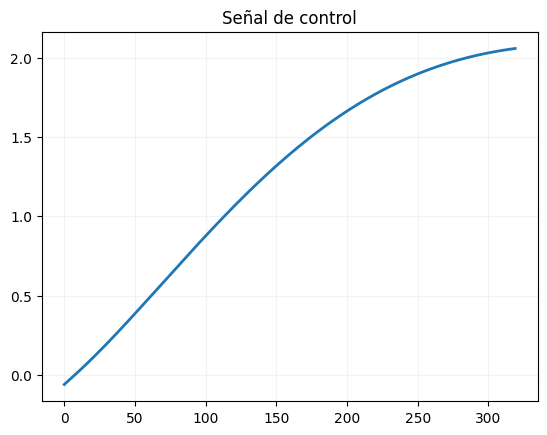

In [6]:
best_individual = population[0]
gene, fitness = best_individual
print("Mejor cromosoma:", gene)

DC = dibujacontrol()
DC.dibujar(gene[0],gene[1], gene[2])

## 5. Mejora mediante operador de mutación guiado por gradiente

### 5.1. Motivación

El AG estándar aplica mutaciones gaussianas isotrópicas: la perturbación es igual en todas las direcciones del espacio de parámetros. Sin embargo, es posible **aprovechar información adicional** sobre la estructura del problema para guiar las mutaciones hacia regiones más prometedoras.

La idea parte de la teoría de descenso por gradiente. Para el controlador PID se puede estimar la *dirección* del gradiente de la pérdida sin conocer su magnitud exacta.

### 5.2. Derivación de la dirección del gradiente

Aplicando la regla de la cadena sobre la función de pérdida $\mathcal{L}$ respecto a las ganancias:

$$\frac{\partial \mathcal{L}}{\partial K_p} = \frac{\partial \mathcal{L}}{\partial \omega} \cdot f'(V) \cdot P_{\text{raw}}$$

$$\frac{\partial \mathcal{L}}{\partial K_i} = \frac{\partial \mathcal{L}}{\partial \omega} \cdot f'(V) \cdot I_{\text{raw}}$$

$$\frac{\partial \mathcal{L}}{\partial K_d} = \frac{\partial \mathcal{L}}{\partial \omega} \cdot f'(V) \cdot D_{\text{raw}}$$

donde $f'(V)$ es la derivada (desconocida) de la dinámica del motor respecto a la tensión, y $P_{\text{raw}}$, $I_{\text{raw}}$, $D_{\text{raw}}$ son los términos *sin escalar* (es decir, el error $e$, la integral acumulada de $e$, y la derivada de $e$, respectivamente).

El factor escalar $\frac{\partial \mathcal{L}}{\partial \omega} \cdot f'(V)$ es **común a los tres componentes** y su signo es desconocido, por lo que la dirección absoluta del gradiente no es fiable. Sin embargo, la **dirección relativa** entre componentes sí es informativa: indica en qué proporción debe modificarse cada ganancia respecto a las demás.

### 5.3. Estimación práctica

Durante cada evaluación de *fitness*, el controlador registra las medias temporales de los términos sin escalar:

$$\hat{g} = \left(\overline{e(t)},\ \overline{\int e\, dt},\ \overline{\frac{de}{dt}}\right)$$

Este vector se normaliza a longitud unitaria para obtener únicamente la **dirección**:

$$\hat{g}_{\text{norm}} = \frac{\hat{g}}{\|\hat{g}\|}$$

El registro de gradientes se almacena en un diccionario indexado por las ganancias $(K_p, K_i, K_d)$, de modo que cada individuo evaluado durante el AG estándar deja disponible su dirección de gradiente para la fase siguiente.

### 5.4. Operador de mutación guiado

El nuevo operador aplica la mutación proyectando el ruido gaussiano **a lo largo de la dirección del gradiente normalizado**:

$$\mathbf{K}' = \mathbf{K} - \epsilon \cdot \hat{g}_{\text{norm}}$$

donde $\epsilon = |\mathcal{N}(0, \sigma)|$ es un paso positivo muestreado de una distribución seminormal. El signo negativo indica descenso, aunque dada la ambigüedad de signo comentada, en la práctica la dirección efectiva depende de la orientación de $\hat{g}$ en cada punto.

Si no hay información de gradiente disponible para un individuo (gen no evaluado previamente), se aplica mutación gaussiana isótropa como fallback.

### 5.5. Inicialización del registro de gradientes

Para que el operador pueda aprovechar los gradientes desde el inicio, el registro del AG estándar se **comparte** con el nuevo optimizador mediante `registry.update(...)`. Así, los ~20 000 evaluaciones de la primera fase (100 individuos × 200 generaciones) proporcionan inmediatamente una cobertura densa del espacio de búsqueda.

In [7]:
from typing import Callable
from genetic_metaheuristics.typing import Gene, Individual
from genetic_metaheuristics.operators.reals import RealsOperator
class PIDGradientOperator(RealsOperator):
    def __init__(
        self,
        gene_fitness_func: Callable[[np.ndarray], float],
        optimizer_registry: dict,
        mutation_scale: float = 0.1,
    ):
        self.mutation_scale = mutation_scale
        self.gene_fitness_func = gene_fitness_func
        self.optimizer_registry = optimizer_registry
        
    def __call__(
        self,
        individual: Individual[np.ndarray],
    ) -> Individual[np.ndarray]:
        gene, fitness = individual
        gradient = self.optimizer_registry.get(tuple(gene), (0.0, 0.0, 0.0))
        norm = np.linalg.norm(gradient)
        gradient_normalized = gradient / norm if norm > 1e-10 else np.zeros_like(gradient)

        
        # Perform mutation randomly along the gradient direction
        mutation = np.random.normal(loc=0.0, scale=self.mutation_scale, size=gene.shape)
        mutated_gene = gene - mutation * np.array(gradient_normalized)
        new_fitness = self.gene_fitness_func(mutated_gene)
        new_individual = (mutated_gene, new_fitness)
        return new_individual
    


### 5.6. Configuración del AG con operador de gradiente

Se usa una configuración distinta a la del AG estándar:
- Mayor probabilidad de mutación ($p_m = 0{,}9$) para que el operador guiado se aplique frecuentemente.
- Menor probabilidad de cruce ($p_c = 0{,}1$), ya que la información de gradiente hace el cruce menos necesario para la exploración.
- El operador por defecto (`'gaussian'`) se sustituye por el `PIDGradientOperator` una vez instanciado.
- El registro de gradientes se inicializa con los datos acumulados durante el AG estándar.

In [8]:
pid_genetic_gradient_optimizer = PIDGeneticOptimizer(
    gene_length=3,
    cross_prob=0.1,
    mut_prob=0.9,
    tournament_participants=2,
    operator='gaussian',
    maximize=False,
    seed=None,
    on_keyboard_interrupt='raise',
    max_workers=None
)

pid_genetic_gradient_optimizer.set_controller(Controller())
pid_genetic_gradient_optimizer.set_performance(Performance())

pid_genetic_gradient_optimizer.controller.registry.update(pid_genetic_optimizer.controller.registry)  # Share the registry with the previous optimizer

gradient_operator = PIDGradientOperator(
    gene_fitness_func=pid_genetic_gradient_optimizer.calculate_gene_fitness,
    optimizer_registry=pid_genetic_gradient_optimizer.controller.registry,
    mutation_scale=0.1
)
pid_genetic_gradient_optimizer.operator = gradient_operator

### 5.7. Fase de evolución

Se ejecutan otras 200 generaciones sobre una población de 100 individuos. Las semillas de NumPy y del módulo `random` se fijan para garantizar la reproducibilidad.

In [9]:
random.seed(1234)
np.random.seed(1234)
population = pid_genetic_gradient_optimizer.evolve(population, num_generations=200) # type: ignore

Generaciones:  12%|█▎        | 25/200 [00:05<00:37,  4.65it/s]/tmp/ipykernel_100956/193178361.py:118: RuntimeWarning: overflow encountered in scalar divide
  self.derivatives.append(D / self.Kd if abs(self.Kd) > 1e-10 else (error - error_anterior) / self.controller_t)
/tmp/ipykernel_100956/193178361.py:114: RuntimeWarning: overflow encountered in scalar multiply
  term1 = Td / (Td + N * h) * self.previous_D
Generaciones:  17%|█▋        | 34/200 [00:07<00:35,  4.64it/s]/home/hakaivulpes/.local/share/uv/python/cpython-3.12.12-linux-x86_64-gnu/lib/python3.12/statistics.py:195: RuntimeWarning: invalid value encountered in scalar add
  partials[d] = partials_get(d, 0) + n
Generaciones:  18%|█▊        | 37/200 [00:08<00:36,  4.48it/s]/home/hakaivulpes/vault/upm/c3/s2/rbt/personal/rbt-genetic-pid/.venv/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2767: RuntimeWarning: overflow encountered in dot
  sqnorm = x.dot(x)
Generaciones:  28%|██▊       | 56/200 [00:12<00:32,  4.37it/s]/tmp/ipy


Fitness óptimo: 0.191
Mejor individuo [0.50780455 0.19676518 0.00066379]


Mejor cromosoma: [0.50780455 0.19676518 0.00066379]
Overshoot:  0.02460616802318981
d:  0.04519485310257917
Ess:  0.07535557398856782
Ts: 0.0463239409959242


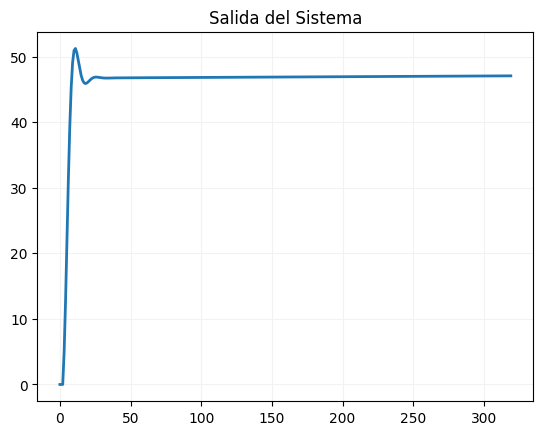

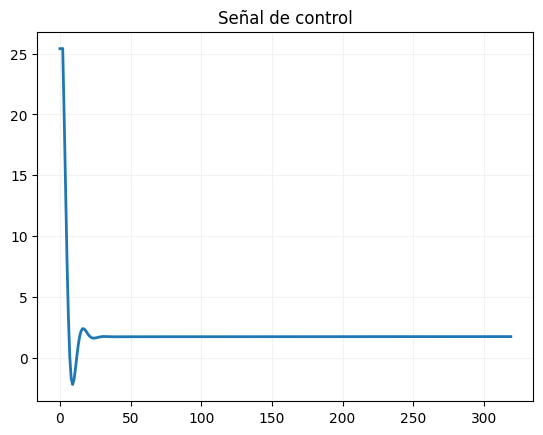

In [10]:
best_individual = population[0]
gene, fitness = best_individual
print("Mejor cromosoma:", gene)

DC = dibujacontrol()
DC.dibujar(gene[0],gene[1], gene[2])

## 6. Conclusiones

El proceso de optimización se ha articulado en dos fases complementarias:

1. **AG estándar (mutación gaussiana isótropa):** Explora el espacio de parámetros de forma amplia gracias a una población de 100 individuos y 200 generaciones.

2. **AG con mutación guiada por gradiente:** Refina las soluciones obtenidas orientando las perturbaciones según la información de la derivada parcial disponible, concentrando la búsqueda en las direcciones más prometedoras del espacio de parámetros.

Esta estrategia híbrida combina la **robustez global** de los algoritmos evolutivos con la **eficiencia local** de la información de gradiente, sin requerir conocer la función de transferencia exacta del motor — la dirección del gradiente se estima directamente a partir de las señales internas del controlador durante la simulación.